In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df = pd.read_csv('C:\\Users\\win\\Downloads\\station_data_dataverse.csv')
print('Data Loaded Successfully!')
print('Total Rows:', df.shape[0])
print('Total Columns:', df.shape[1])
df.head(3)

Data Loaded Successfully!
Total Rows: 3395
Total Columns: 24


,sessionId,kwhTotal,dollars,created,ended,startTime,endTime,chargeTimeHrs,weekday,platform,...,managerVehicle,facilityType,Mon,Tues,Wed,Thurs,Fri,Sat,Sun,reportedZip
0,1366563,7.78,0.00,0014-11-18 15:40:26,0014-11-18 17:11:04,15,17,1.510556,Tue,android,...,0,3,0,1,0,0,0,0,0,0
1,3075723,9.74,0.00,0014-11-19 17:40:26,0014-11-19 19:51:04,17,19,2.177222,Wed,android,...,0,3,0,0,1,0,0,0,0,0
2,4228788,6.76,0.58,0014-11-21 12:05:46,0014-11-21 16:46:04,12,16,4.671667,Fri,android,...,0,3,0,0,0,0,1,0,0,0


In [12]:
cols_to_drop = ['sessionId', 'userId', 'created', 'ended']
df_clean = df.drop(columns=cols_to_drop)
print('Remaining Columns:', df_clean.shape[1])

Remaining Columns: 20


In [13]:
median_val = df_clean['distance'].median()
df_clean['distance'] = df_clean['distance'].fillna(median_val)
print('Missing values in distance:', df_clean['distance'].isnull().sum())

Missing values in distance: 0


In [14]:
df_clean = pd.get_dummies(df_clean, columns=['platform'], drop_first=True)

if 'weekday' in df_clean.columns:
  df_clean = df_clean.drop(columns=['weekday'])

print('Columns after encoding:')
print(df_clean.columns.tolist())

Columns after encoding:
['kwhTotal', 'dollars', 'startTime', 'endTime', 'chargeTimeHrs', 'distance', 'stationId', 'locationId', 'managerVehicle', 'facilityType', 'Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun', 'reportedZip', 'platform_ios', 'platform_web']


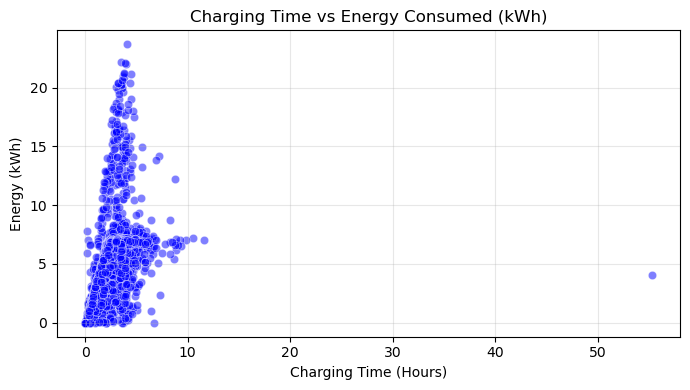

In [9]:
plt.figure(figsize=(7, 4))
sns.scatterplot(
    x='chargeTimeHrs', y='kwhTotal', data=df_clean, color='blue', alpha=0.5
)
plt.title('Charging Time vs Energy Consumed (kWh)')
plt.xlabel('Charging Time (Hours)')
plt.ylabel('Energy (kWh)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

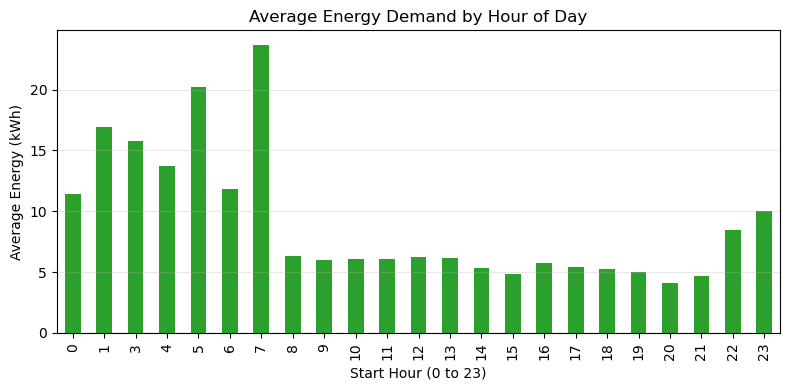

In [15]:
plt.figure(figsize=(8, 4))
hourly_avg = df_clean.groupby('startTime')['kwhTotal'].mean()
hourly_avg.plot(kind='bar', color='#2ca02c')
plt.title('Average Energy Demand by Hour of Day')
plt.xlabel('Start Hour (0 to 23)')
plt.ylabel('Average Energy (kWh)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

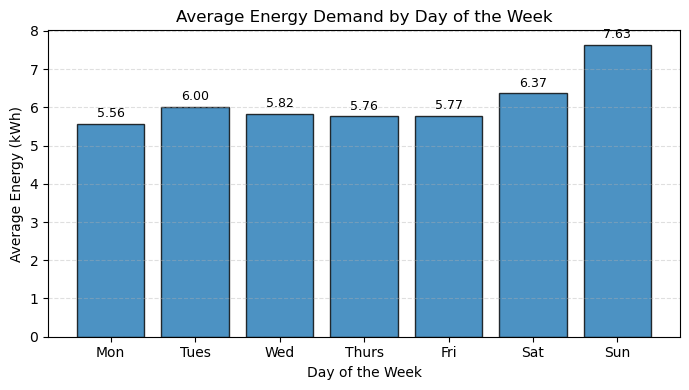

In [16]:
days = ['Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun']
day_avg_kwh = [df_clean[df_clean[d] == 1]['kwhTotal'].mean() for d in days]
plt.figure(figsize=(7, 4))
bars = plt.bar(days, day_avg_kwh, color='#1f77b4', edgecolor='black', alpha=0.8)
plt.title('Average Energy Demand by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Energy (kWh)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 0.1,
      f'{yval:.2f}',
      ha='center',
      va='bottom',
      fontsize=9,
  )

plt.tight_layout()
plt.show()

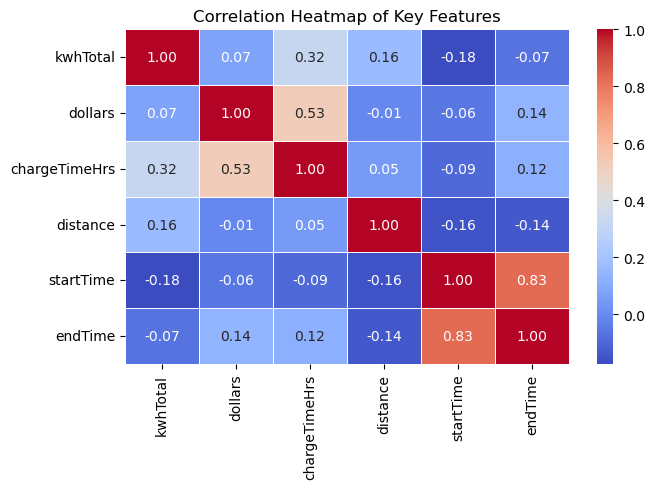

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ['kwhTotal', 'dollars', 'chargeTimeHrs', 'distance', 'startTime', 'endTime']

plt.figure(figsize=(7, 5))
sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Key Features')
plt.tight_layout()
plt.show()

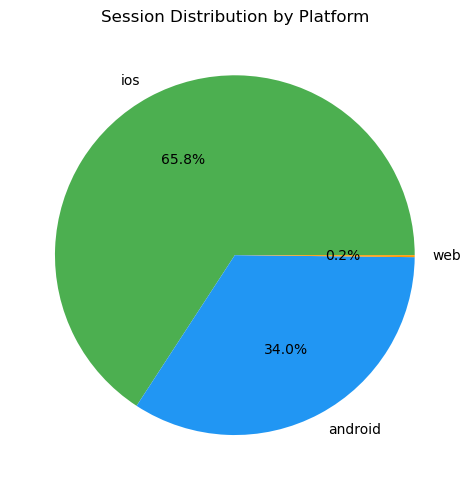

In [18]:
plt.figure(figsize=(5, 5))
df['platform'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#4CAF50', '#2196F3', '#FF9800'])
plt.title('Session Distribution by Platform')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [19]:
top_stations = df.groupby('stationId')['kwhTotal'].sum().sort_values(ascending=False).head(5)
print("--- Top 5 Busiest Stations by Total kWh ---")
print(top_stations)

--- Top 5 Busiest Stations by Total kWh ---
stationId
369001    1871.25
474204    1304.34
955429     934.61
250527     658.00
228137     629.16
Name: kwhTotal, dtype: float64


In [15]:
y = df_clean['kwhTotal']
X = df_clean.drop(columns=['kwhTotal', 'dollars'])

print('Features (X) count:', X.shape[1])
print('Target (y): kwhTotal')

Features (X) count: 18
Target (y): kwhTotal


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train rows:', X_train.shape[0])
print('Test rows:', X_test.shape[0])

Train rows: 2716
Test rows: 679


## Linear Regression

In [17]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print('Linear Regression completed.')

Linear Regression completed.


## Decision Tree

In [18]:
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
print('Decision Tree completed.')

Decision Tree completed.


## Random Forest

In [20]:
rf = RandomForestRegressor(
    n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print('Random Forest completed.')

Random Forest completed.


## Evaluation Metrics

In [21]:
def print_score(name, y_true, y_pred):
  mae = mean_absolute_error(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  r2 = r2_score(y_true, y_pred)
  print(f'{name:20s} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R2: {r2:.3f}')
print_score('Linear Regression', y_test, lr_pred)
print_score('Decision Tree', y_test, dt_pred)
print_score('Random Forest', y_test, rf_pred)

Linear Regression    | MAE: 1.651 | RMSE: 3.285 | R2: -0.408
Decision Tree        | MAE: 1.278 | RMSE: 2.196 | R2: 0.371
Random Forest        | MAE: 1.152 | RMSE: 1.969 | R2: 0.494


## Feature Importance

In [22]:
importances = rf.feature_importances_
feature_names = X.columns

print('--- Top 5 Important Features ---')
for name, imp in sorted(
    zip(feature_names, importances), key=lambda x: x[1], reverse=True
)[:5]:
  print(f'{name:20s}: {imp*100:.1f}%')

--- Top 5 Important Features ---
chargeTimeHrs       : 47.9%
locationId          : 13.0%
startTime           : 11.4%
distance            : 10.7%
endTime             : 6.5%


In [23]:
# Sample input for testing prediction
new_car_data = pd.DataFrame([{
    'startTime': 16,
    'endTime': 20,
    'chargeTimeHrs': 4.0,
    'distance': 15.0,
    'stationId': 366832,
    'locationId': 978130,
    'managerVehicle': 0,
    'facilityType': 2,
    'Mon': 0, 'Tues': 0, 'Wed': 0, 'Thurs': 0, 'Fri': 1, 'Sat': 0, 'Sun': 0,
    'reportedZip': 0,
    'platform_ios': True,
    'platform_web': False
}])

# Make prediction using the trained Random Forest model
predicted_kwh = rf.predict(new_car_data)[0]

print("=" * 45)
print(f"Predicted Energy Demand: {predicted_kwh:.2f} kWh")
print("=" * 45)

Predicted Energy Demand: 5.83 kWh


In [24]:
# Multiple new vehicles data for prediction
multiple_cars_data = pd.DataFrame([
    {
        'startTime': 9,
        'endTime': 11,
        'chargeTimeHrs': 2.0,
        'distance': 8.5,
        'stationId': 582873,
        'locationId': 461655,
        'managerVehicle': 0,
        'facilityType': 3,
        'Mon': 0, 'Tues': 0, 'Wed': 0, 'Thurs': 0, 'Fri': 0, 'Sat': 0, 'Sun': 1,
        'reportedZip': 0,
        'platform_ios': False,
        'platform_web': False
    },
    {
        'startTime': 13,
        'endTime': 18,
        'chargeTimeHrs': 5.0,
        'distance': 30.0,
        'stationId': 129465,
        'locationId': 461655,
        'managerVehicle': 1,
        'facilityType': 2,
        'Mon': 1, 'Tues': 0, 'Wed': 0, 'Thurs': 0, 'Fri': 0, 'Sat': 0, 'Sun': 0,
        'reportedZip': 0,
        'platform_ios': True,
        'platform_web': False
    }
])

# Generate predictions using the trained Random Forest model
predictions = rf.predict(multiple_cars_data)

# Display results
print("=" * 50)
print(f"Scenario 1 (2 Hours, Short Session): {predictions[0]:.2f} kWh")
print(f"Scenario 2 (5 Hours, Long Session) : {predictions[1]:.2f} kWh")
print("=" * 50)

Scenario 1 (2 Hours, Short Session): 4.68 kWh
Scenario 2 (5 Hours, Long Session) : 6.47 kWh
